## Analyse de la régression linéaire

#### initialisation pré model

In [1]:
import numpy as np
import pandas as pd

## Creation du DF
df = pd.read_csv('data/tmp/in-preprocessed_df.csv', low_memory=False)

low, high = df["valeur_fonciere"].quantile([0.01, 0.99])
df = df[df["valeur_fonciere"].between(low, high)]


### Préparation des colomnes

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder

y = np.log1p(df["valeur_fonciere"])

dep_cols = [c for c in df.columns if c.startswith('code_departement')]

features = ["surface_reelle_bati", "nombre_pieces_principales", "type_local",
            "code_postal", "longitude", "latitude"] + dep_cols
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = ["surface_reelle_bati", "nombre_pieces_principales", "longitude", "latitude"]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("type", OneHotEncoder(handle_unknown="ignore"), ["type_local"]),
    ("dep", "passthrough", dep_cols),
    ("zip", TargetEncoder(), ["code_postal"]),
])

### Preparation des modèles

In [3]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Ridge": Ridge(),
    "DecisionTree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "RandomForest": RandomForestRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}


### Entrainement et évaluation

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

base = DummyRegressor(strategy="median").fit(X_train, y_train)
base_pred = np.expm1(base.predict(X_test))
true = np.expm1(y_test)
baseline_mae = mean_absolute_error(true, base_pred)
print(f"MAE de référence : {baseline_mae:,.0f} €")
print("Tout modèle utile doit faire mieux que ce chiffre.")

fitted, preds = {}, {}
results = []
true = np.expm1(y_test)

for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = np.expm1(pipe.predict(X_test))

    fitted[name], preds[name] = pipe, pred

    rmse = mean_squared_error(true, pred) ** 0.5
    mae = mean_absolute_error(true, pred)
    r2 = r2_score(true, pred)
    results.append({"model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

    print(f"   Nom  : {name} (Modèle utilisé)")
    print(f"   MAE  : {mae:,.0f} €  (erreur moyenne)")
    print(f"   RMSE : {rmse:,.0f} €  (pénalise les grosses erreurs)")
    print(f"   R2   : {r2:.3f}  (part de la variance des prix expliquée)")

res = pd.DataFrame(results)
baseline_rmse = mean_squared_error(true, base_pred) ** 0.5


MAE de référence : 72,040 €
Tout modèle utile doit faire mieux que ce chiffre.
   Nom  : Ridge (Modèle utilisé)
   MAE  : 50,447 €  (erreur moyenne)
   RMSE : 73,588 €  (pénalise les grosses erreurs)
   R2   : 0.435  (part de la variance des prix expliquée)
   Nom  : DecisionTree (Modèle utilisé)
   MAE  : 48,486 €  (erreur moyenne)
   RMSE : 67,852 €  (pénalise les grosses erreurs)
   R2   : 0.519  (part de la variance des prix expliquée)
   Nom  : RandomForest (Modèle utilisé)
   MAE  : 47,009 €  (erreur moyenne)
   RMSE : 65,995 €  (pénalise les grosses erreurs)
   R2   : 0.545  (part de la variance des prix expliquée)
   Nom  : GradientBoosting (Modèle utilisé)
   MAE  : 46,340 €  (erreur moyenne)
   RMSE : 65,116 €  (pénalise les grosses erreurs)
   R2   : 0.557  (part de la variance des prix expliquée)


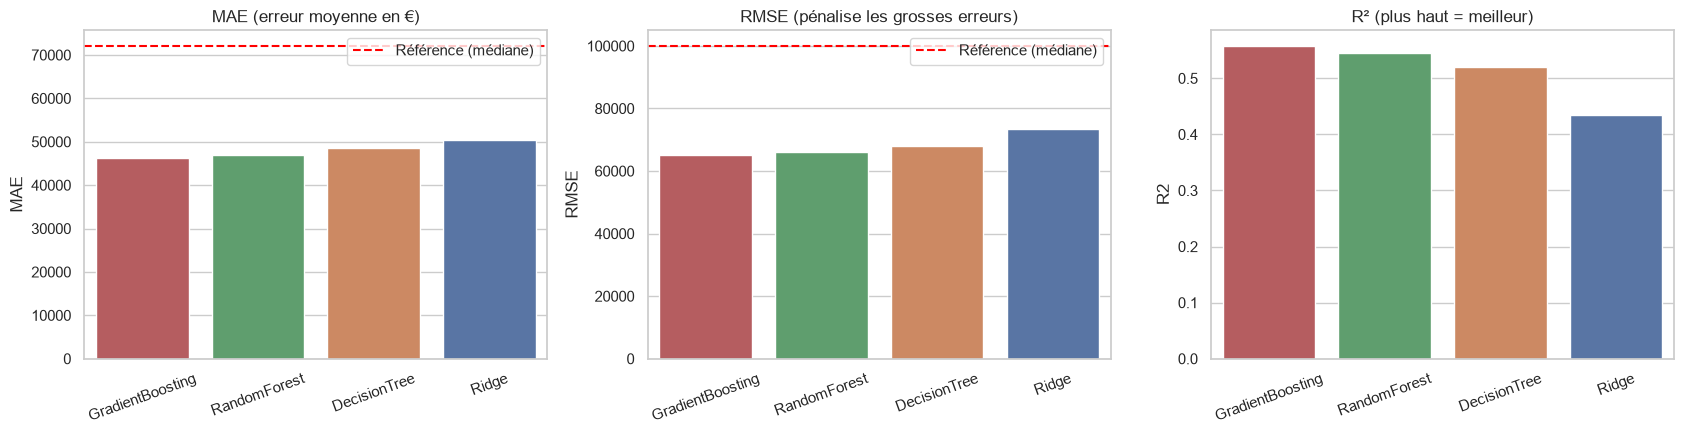

In [6]:
### Comparaison globale des modèles
from matplotlib import pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

res = pd.DataFrame(results)
true = np.expm1(y_test)
true_arr = np.asarray(true)
baseline_rmse = mean_squared_error(true, base_pred) ** 0.5

order = res.sort_values("MAE")["model"].tolist()
order = res.sort_values("MAE")["model"].tolist()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.barplot(data=res, x="model", y="MAE", order=order, hue="model", legend=False, ax=ax[0])
ax[0].axhline(baseline_mae, color="red", ls="--", label="Référence (médiane)")
ax[0].set_title("MAE (erreur moyenne en €)");
ax[0].legend()

sns.barplot(data=res, x="model", y="RMSE", order=order, hue="model", legend=False, ax=ax[1])
ax[1].axhline(baseline_rmse, color="red", ls="--", label="Référence (médiane)")
ax[1].set_title("RMSE (pénalise les grosses erreurs)");
ax[1].legend()

sns.barplot(data=res, x="model", y="R2", order=order, hue="model", legend=False, ax=ax[2])
ax[2].set_title("R² (plus haut = meilleur)")

for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

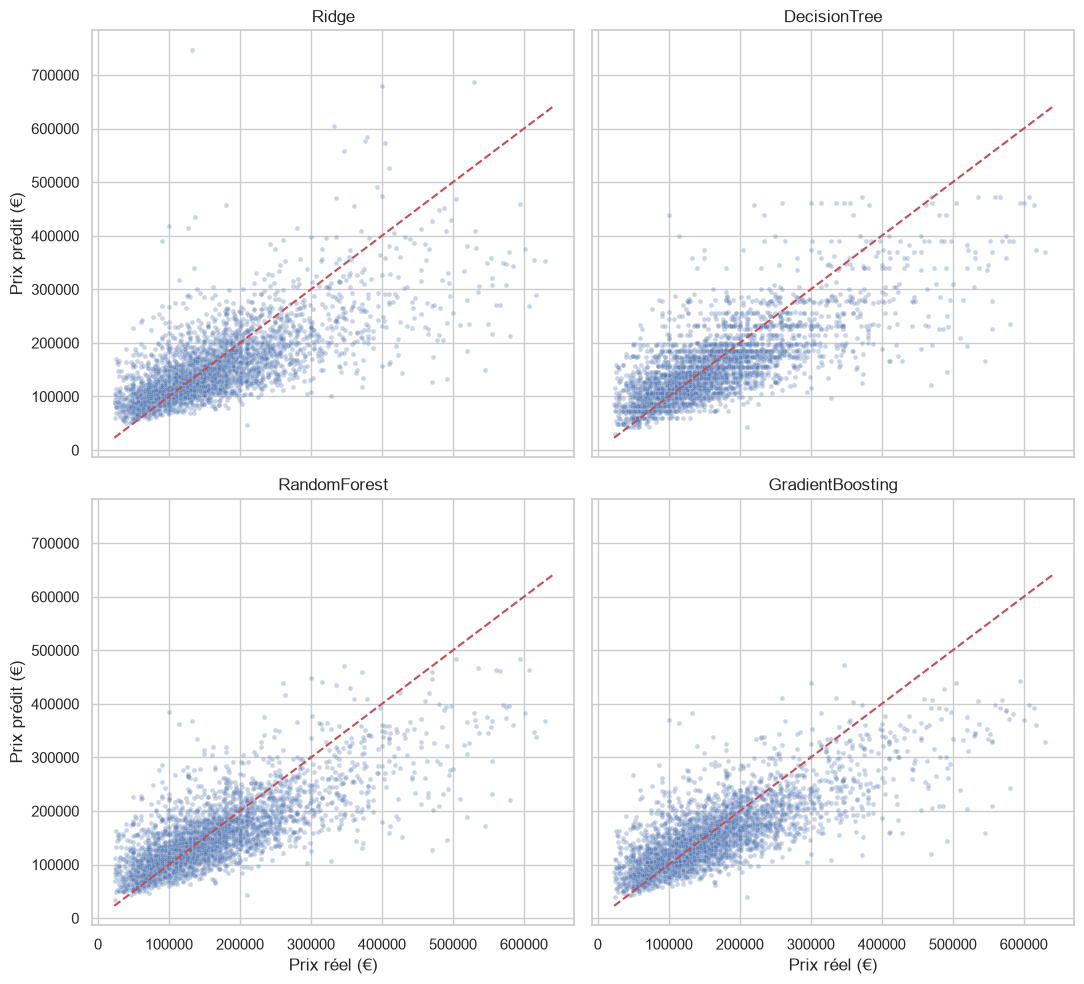

In [7]:
### Prix prédit vs prix réel (les points doivent suivre la diagonale)
idx = np.random.RandomState(42).choice(len(true_arr), min(3000, len(true_arr)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
for a, (name, pred) in zip(axes.ravel(), preds.items()):
    sns.scatterplot(x=true_arr[idx], y=pred[idx], alpha=0.3, s=12, ax=a)
    lim = [true_arr.min(), true_arr.max()]
    a.plot(lim, lim, "r--")
    a.set_title(name)
    a.set_xlabel("Prix réel (€)")
    a.set_ylabel("Prix prédit (€)")
plt.tight_layout()
plt.show()

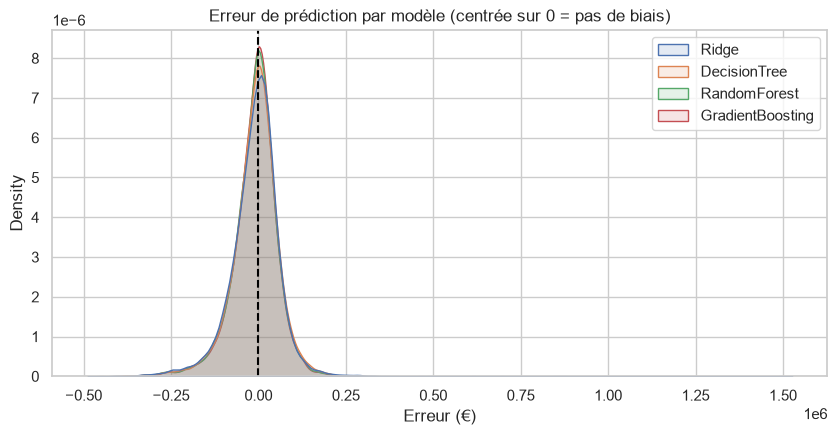

In [8]:
### Distribution des erreurs (prédit - réel)
resid = pd.DataFrame({name: pred - true_arr for name, pred in preds.items()})

plt.figure(figsize=(10, 4.5))
sns.kdeplot(data=resid, common_norm=False, fill=True, alpha=0.15)
plt.axvline(0, color="black", ls="--")
plt.title("Erreur de prédiction par modèle (centrée sur 0 = pas de biais)")
plt.xlabel("Erreur (€)")
plt.show()

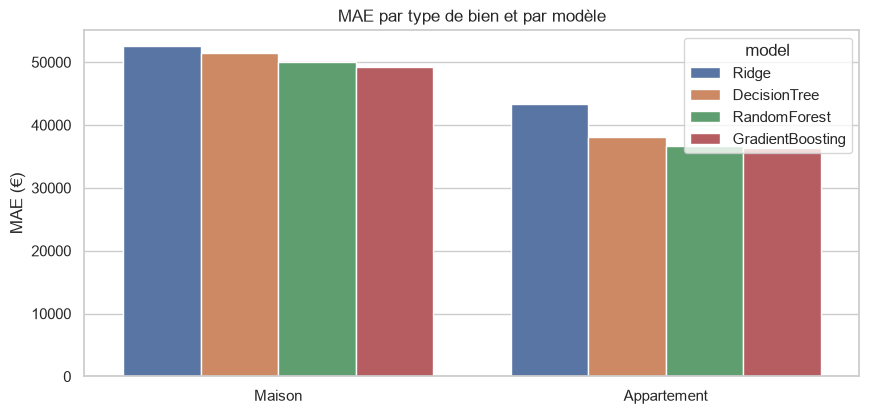

In [9]:
### Erreur par type de bien
type_test = X_test["type_local"].values
long = pd.concat([
    pd.DataFrame({"model": name, "type_local": type_test, "erreur_abs": np.abs(pred - true_arr)})
    for name, pred in preds.items()
])

plt.figure(figsize=(10, 4.5))
sns.barplot(data=long, x="type_local", y="erreur_abs", hue="model", errorbar=None)
plt.title("MAE par type de bien et par modèle")
plt.ylabel("MAE (€)")
plt.xlabel("")
plt.show()

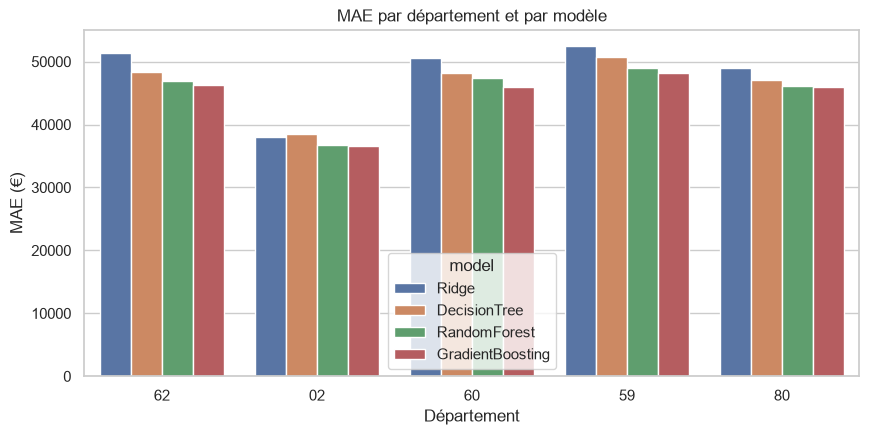

In [10]:
### Erreur par département
dep_test = X_test[dep_cols].astype(int).idxmax(axis=1).str.replace("code_departement_", "", regex=False).values
long_dep = pd.concat([
    pd.DataFrame({"model": name, "departement": dep_test, "erreur_abs": np.abs(pred - true_arr)})
    for name, pred in preds.items()
])

plt.figure(figsize=(10, 4.5))
sns.barplot(data=long_dep, x="departement", y="erreur_abs", hue="model", errorbar=None)
plt.title("MAE par département et par modèle")
plt.ylabel("MAE (€)");
plt.xlabel("Département")
plt.show()

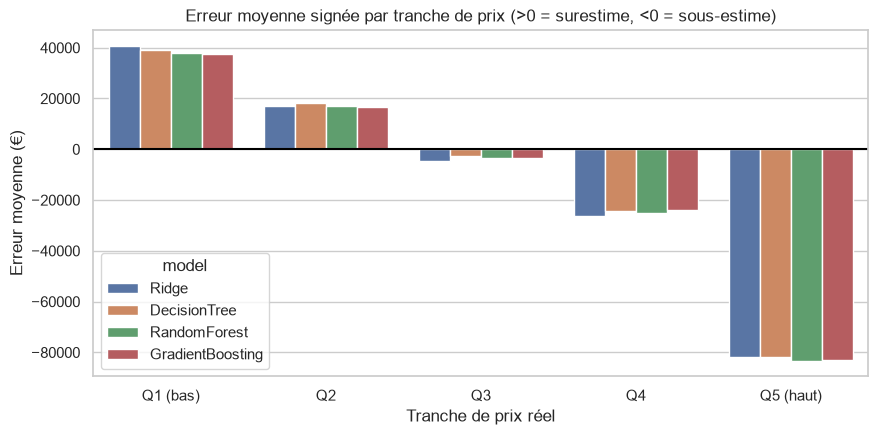

In [11]:
### Erreur selon la tranche de prix réel
bins = pd.qcut(true_arr, 5, labels=["Q1 (bas)", "Q2", "Q3", "Q4", "Q5 (haut)"])
long_bin = pd.concat([
    pd.DataFrame({"model": name, "tranche": bins, "erreur": pred - true_arr})
    for name, pred in preds.items()
])

plt.figure(figsize=(10, 4.5))
sns.barplot(data=long_bin, x="tranche", y="erreur", hue="model", errorbar=None)
plt.axhline(0, color="black")
plt.title("Erreur moyenne signée par tranche de prix (>0 = surestime, <0 = sous-estime)")
plt.ylabel("Erreur moyenne (€)")
plt.xlabel("Tranche de prix réel")
plt.show()

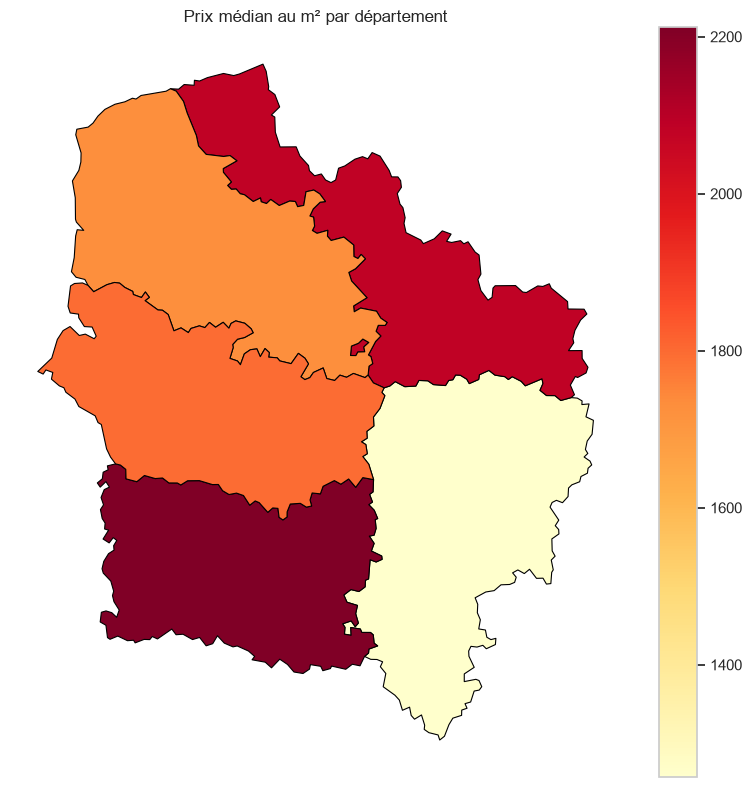

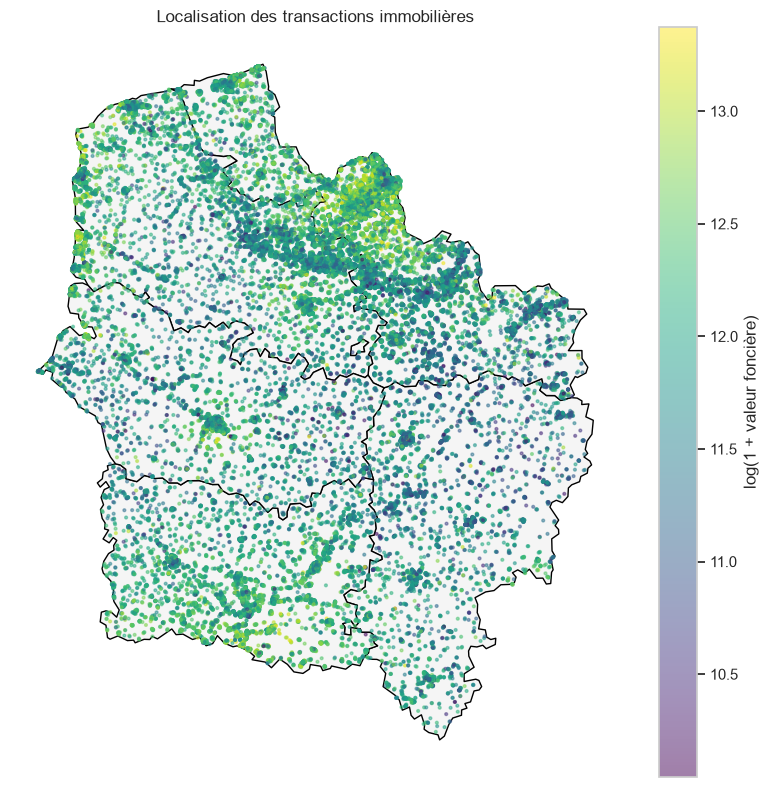

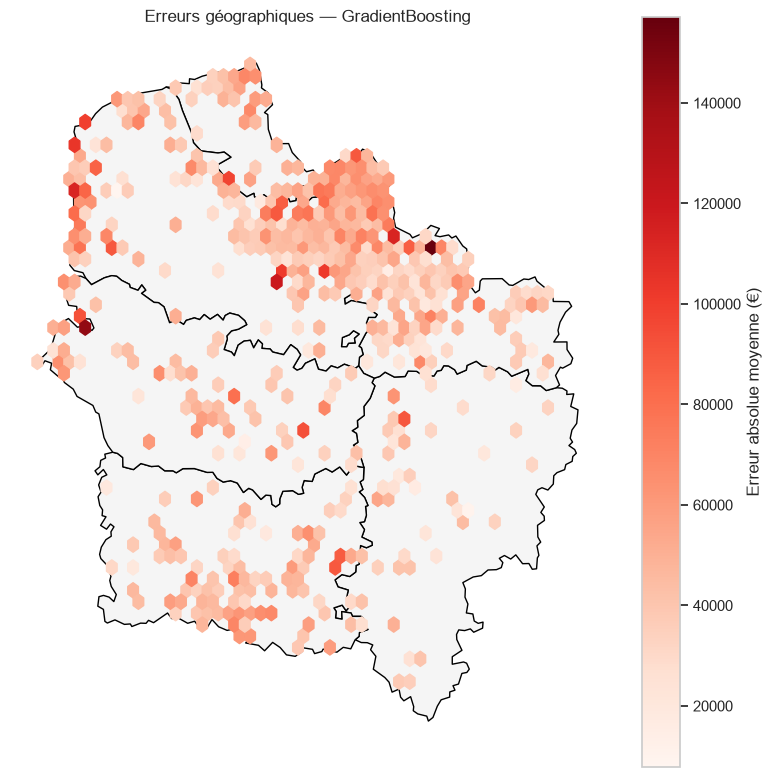

In [18]:

import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load department boundaries
url = (
    "https://raw.githubusercontent.com/gregoiredavid/"
    "france-geojson/master/departements-version-simplifiee.geojson"
)

geo = gpd.read_file(url)
geo["code"] = geo["code"].astype(str).str.zfill(2)

selected_codes = ["02", "59", "60", "62", "80"]
geo = geo[geo["code"].isin(selected_codes)].copy()

# 2. Recover department code from dummy columns
# df is the filtered dataset used in the notebook
df_geo = df.copy()

df_geo["code"] = (
    df_geo[dep_cols]
    .idxmax(axis=1)
    .str.replace("code_departement_", "", regex=False)
)

# Validate that each row has exactly one active department dummy
assert (df_geo[dep_cols].sum(axis=1) == 1).all(), (
    "Some rows do not have exactly one active department dummy."
)

# 3. Calculate price per square meter if not already available
if "prix_m2" not in df_geo.columns:
    df_geo["prix_m2"] = (
            df_geo["valeur_fonciere"]
            / df_geo["surface_reelle_bati"].replace(0, np.nan)
    )

# 4. Department-level statistics
stats = (
    df_geo.groupby("code")
    .agg(
        prix_m2=("prix_m2", "median"),
        ventes=("valeur_fonciere", "size"),
    )
    .reset_index()
)

geo_stats = geo.merge(stats, on="code", how="left")

# MAP 1: Median price per square meter by department
fig, ax = plt.subplots(figsize=(8, 8))

geo_stats.plot(
    column="prix_m2",
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "No data"},
    ax=ax,
)

ax.set_title("Prix médian au m² par département")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# MAP 2: Transaction locations
fig, ax = plt.subplots(figsize=(8, 8))
geo.plot(color="whitesmoke", edgecolor="black", ax=ax)

sc = ax.scatter(
    df_geo["longitude"],
    df_geo["latitude"],
    c=np.log1p(df_geo["valeur_fonciere"]),
    s=4,
    cmap="viridis",
    alpha=0.5,
)

fig.colorbar(sc, ax=ax, label="log(1 + valeur foncière)")
ax.set_title("Localisation des transactions immobilières")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# MAP 3: GradientBoosting absolute errors on the test set
t = X_test[["longitude", "latitude"]].copy()

t["erreur_abs"] = np.abs(
    np.asarray(preds["GradientBoosting"]).ravel()
    - np.asarray(true_arr).ravel()
)

t = t.dropna(subset=["longitude", "latitude", "erreur_abs"])

fig, ax = plt.subplots(figsize=(8, 8))
geo.plot(color="whitesmoke", edgecolor="black", ax=ax)

h = ax.hexbin(
    t["longitude"],
    t["latitude"],
    C=t["erreur_abs"],
    reduce_C_function=np.mean,
    gridsize=50,
    cmap="Reds",
    mincnt=5,
)

fig.colorbar(h, ax=ax, label="Erreur absolue moyenne (€)")
ax.set_title("Erreurs géographiques — GradientBoosting")
ax.set_axis_off()
plt.tight_layout()
plt.show()